# Mental Health Risk Scoring Pipeline
**Workplace & psychological survey → risk score (regression) + risk level (multi-class classification)**

This notebook is an end-to-end, cell-by-cell pipeline that:

1. Loads and audits the survey responses
2. Cleans messy fields (impossible ages, 40+ free-text gender spellings, missing values)
3. Applies **ordinal encoding** to ordered answers (e.g. *Never < Rarely < Sometimes < Often*)
4. Engineers a **0–100 mental-health risk score** and a **Low / Moderate / High** risk level
5. Explores the data (EDA)
6. Performs **three-stage feature selection** (mutual information → random-forest importance → RFECV)
7. Trains and tunes **multi-class classifiers** and **regression models**
8. Evaluates on a held-out test set, explains the model (permutation importance) and checks subgroup performance
9. Wraps everything in a `predict_risk()` function that returns a score, level and a suggested wellness action
10. Saves the trained artifacts

> **Important – what this dataset contains.** The uploaded `survey.csv` is the *Mental Health in Tech Survey* (1,259 rows, 27 columns).
> It covers **work environment, employer support, stigma, family history, age, gender and country**, but it has **no columns for
> stress level, sleep hours or physical activity**. Cell 4 checks this explicitly. The pipeline is written so that if you later add
> `stress_level`, `sleep_hours` or `physical_activity` columns they are picked up automatically (demonstrated in Cell 29).

## 1 · Setup

In [1]:
import os, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif, RFECV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# locate the data file (works locally and in the sandbox)
DATA_PATH = next(p for p in ["survey.csv", "/mnt/user-data/uploads/survey.csv"] if os.path.exists(p))
ARTIFACT_DIR = "artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

print("Data file     :", DATA_PATH)
print("Artifacts dir :", ARTIFACT_DIR)
print("Libraries     : numpy", np.__version__, "| pandas", pd.__version__)

Data file     : /mnt/user-data/uploads/survey.csv
Artifacts dir : artifacts
Libraries     : numpy 2.5.4 | pandas 3.0.6


## 2 · Load the data

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 1,259   Columns: 27


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,No,Yes,Yes,Not sure,No,Yes,Yes,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,No,No,Don't know,No,Don't know,Don't know,Don't know,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,No,Yes,No,No,No,No,Don't know,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,No,Yes,No,Yes,No,No,No,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,Yes,Yes,Yes,No,Don't know,Don't know,Don't know,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


## 3 · Data audit – types, missing values, cardinality

In [3]:
audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(1),
    "n_unique": df_raw.nunique(),
})
print("Age range as recorded:", df_raw["Age"].min(), "to", df_raw["Age"].max())
audit

Age range as recorded: -1726 to 99999999999


,dtype,missing,missing_%,n_unique
Timestamp,str,0,0.0,1246
Age,int64,0,0.0,53
Gender,str,0,0.0,49
Country,str,0,0.0,48
state,str,515,40.9,45
self_employed,str,18,1.4,2
family_history,str,0,0.0,2
treatment,str,0,0.0,2
work_interfere,str,264,21.0,4
no_employees,str,0,0.0,6


## 4 · Coverage check – which of the requested factors exist in this file?
The brief asks for stress, sleep, work environment, physical activity and lifestyle. Rather than assume, we check.

In [4]:
REQUESTED_FACTORS = {
    "Self-reported stress":       ["stress_level"],
    "Sleep hours":                ["sleep_hours"],
    "Physical activity":          ["physical_activity"],
    "Work environment":           ["remote_work", "tech_company", "no_employees", "benefits", "care_options",
                                   "wellness_program", "seek_help", "anonymity", "leave", "coworkers", "supervisor"],
    "Stigma / perceived consequences": ["mental_health_consequence", "phys_health_consequence",
                                        "mental_health_interview", "phys_health_interview",
                                        "mental_vs_physical", "obs_consequence"],
    "Lifestyle / background":     ["Age", "Gender", "Country", "self_employed", "family_history"],
    "Symptom impact & care-seeking (target)": ["work_interfere", "treatment"],
}

rows = []
for factor, cols in REQUESTED_FACTORS.items():
    present = [c for c in cols if c in df_raw.columns]
    missing = [c for c in cols if c not in df_raw.columns]
    rows.append({"factor": factor, "present": len(present), "absent": len(missing),
                 "absent_columns": ", ".join(missing) if missing else "-"})
pd.DataFrame(rows).set_index("factor")

,present,absent,absent_columns
factor,,,
Self-reported stress,0,1,stress_level
Sleep hours,0,1,sleep_hours
Physical activity,0,1,physical_activity
Work environment,11,0,-
Stigma / perceived consequences,6,0,-
Lifestyle / background,5,0,-
Symptom impact & care-seeking (target),2,0,-


## 5 · Cleaning
Decisions made here:

| Issue | Treatment |
|---|---|
| `Timestamp`, `comments` | Dropped – identifiers / free text |
| `state` | Dropped – 41% missing and only applicable to US respondents |
| `Age` has values like −1726, 5, 329, 99999999999 | Values outside 18–75 → `NaN`; imputed later **inside the ML pipeline** (so no test-set leakage) |
| `Gender` has 49 spellings | Normalised to `Male`, `Female`, `Other` |
| `Country` has 48 values | Grouped to US, UK, Canada, Germany, Other |
| `self_employed` has 18 missing | Filled with `No` (88% majority) |
| `work_interfere` has 264 missing | Missing means *not applicable* (no condition reported) → new level `None` |

In [5]:
MALE   = {"male", "m", "man", "mail", "maile", "make", "mal", "msle", "malr", "male-ish",
          "cis male", "cis man", "male (cis)", "guy (-ish) ^_^"}
FEMALE = {"female", "f", "woman", "femail", "femake", "cis female", "female (cis)", "cis-female/femme"}

def normalise_gender(value):
    v = str(value).strip().lower()
    if v in MALE:   return "Male"
    if v in FEMALE: return "Female"
    return "Other"            # non-binary, trans, ambiguous and unparseable entries

TOP_COUNTRIES = ["United States", "United Kingdom", "Canada", "Germany"]

def clean_survey(df):
    out = df.copy()
    out = out.drop(columns=[c for c in ["Timestamp", "comments", "state"] if c in out.columns])

    if "Age" in out.columns:
        out["Age"] = pd.to_numeric(out["Age"], errors="coerce")
        out.loc[(out["Age"] < 18) | (out["Age"] > 75), "Age"] = np.nan
    if "Gender" in out.columns:
        out["Gender"] = out["Gender"].map(normalise_gender)
    if "Country" in out.columns:
        out["Country"] = out["Country"].where(out["Country"].isin(TOP_COUNTRIES), "Other")
    if "self_employed" in out.columns:
        out["self_employed"] = out["self_employed"].fillna("No")
    if "work_interfere" in out.columns:
        out["work_interfere"] = out["work_interfere"].fillna("None")
    return out

df_clean = clean_survey(df_raw)
print("Shape after cleaning:", df_clean.shape)
print("\nInvalid ages set to NaN:", int(df_clean["Age"].isna().sum()))
print("\nGender:\n", df_clean["Gender"].value_counts().to_string())
print("\nCountry:\n", df_clean["Country"].value_counts().to_string())
print("\nRemaining missing values:\n", df_clean.isna().sum()[lambda s: s > 0].to_string())

Shape after cleaning: (1259, 24)

Invalid ages set to NaN: 8

Gender:
 Gender
Male      992
Female    247
Other      20

Country:
 Country
United States     751
Other             206
United Kingdom    185
Canada             72
Germany            45

Remaining missing values:
 Age    8


## 6 · Ordinal encoding
Every ordered answer is mapped to integers that preserve its order.

Design choices:
* **Yes / No** → 0 / 1
* **No / Don't know / Yes** → 0 / 1 / 2 (treating "Don't know" as the midpoint)
* **No / Maybe / Yes** → 0 / 1 / 2
* **Frequency** (`work_interfere`) → None 0 < Never 1 < Rarely 2 < Sometimes 3 < Often 4
* **Company size** and **ease of taking leave** → their natural order
* **Nominal** fields with no order (`Gender`, `Country`) → one-hot, *not* ordinal

The optional maps at the bottom let the pipeline accept `stress_level`, `physical_activity` and `sleep_hours` if you add them.

In [6]:
YES_NO = {"No": 0, "Yes": 1}
YN_DK  = {"No": 0, "Don't know": 1, "Not sure": 1, "Yes": 2}
YMN    = {"No": 0, "Maybe": 1, "Yes": 2}
SOME   = {"No": 0, "Some of them": 1, "Yes": 2}
LEAVE  = {"Very difficult": 0, "Somewhat difficult": 1, "Don't know": 2, "Somewhat easy": 3, "Very easy": 4}
SIZE   = {"1-5": 0, "6-25": 1, "26-100": 2, "100-500": 3, "500-1000": 4, "More than 1000": 5}
FREQ   = {"None": 0, "Never": 1, "Rarely": 2, "Sometimes": 3, "Often": 4}

ORDINAL_MAPS = {
    "work_interfere": FREQ, "no_employees": SIZE, "leave": LEAVE,
    "self_employed": YES_NO, "family_history": YES_NO, "treatment": YES_NO,
    "remote_work": YES_NO, "tech_company": YES_NO, "obs_consequence": YES_NO,
    "benefits": YN_DK, "care_options": YN_DK, "wellness_program": YN_DK,
    "seek_help": YN_DK, "anonymity": YN_DK, "mental_vs_physical": YN_DK,
    "mental_health_consequence": YMN, "phys_health_consequence": YMN,
    "mental_health_interview": YMN, "phys_health_interview": YMN,
    "coworkers": SOME, "supervisor": SOME,
}

# Optional lifestyle columns - only used when present in the data
OPTIONAL_ORDINAL_MAPS = {
    "stress_level":      {"low": 0, "medium": 1, "moderate": 1, "high": 2, "very high": 3},
    "physical_activity": {"none": 0, "low": 1, "moderate": 2, "high": 3},
}
OPTIONAL_NUMERIC = ["sleep_hours"]
NOMINAL_COLS = ["Gender", "Country"]

def encode_features(df_clean, feature_columns=None):
    out = df_clean.copy()
    for col, mapping in {**ORDINAL_MAPS, **OPTIONAL_ORDINAL_MAPS}.items():
        if col not in out.columns:
            continue
        lookup = {k.lower(): v for k, v in mapping.items()}
        encoded = out[col].astype("string").str.strip().str.lower().map(lookup).astype(float)
        unseen = out[col].notna() & encoded.isna()
        if unseen.any():
            raise ValueError(f"Unrecognised answers in '{col}': {sorted(out.loc[unseen, col].astype(str).unique())}")
        out[col] = encoded
    for col in OPTIONAL_NUMERIC:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    out = pd.get_dummies(out, columns=[c for c in NOMINAL_COLS if c in out.columns], dtype=int)
    if feature_columns is not None:
        out = out.reindex(columns=feature_columns, fill_value=0)
    return out

df_enc = encode_features(df_clean)

# show the encoding scheme that was applied
scheme = pd.DataFrame({"column": list(ORDINAL_MAPS),
                       "encoding (order → code)": [" < ".join(f"{k}={v}" for k, v in m.items()) for m in ORDINAL_MAPS.values()]})
print(f"Encoded frame: {df_enc.shape[0]:,} rows x {df_enc.shape[1]} columns "
      f"(all numeric: {all(pd.api.types.is_numeric_dtype(t) for t in df_enc.dtypes)})")
scheme.set_index("column")

Encoded frame: 1,259 rows x 30 columns (all numeric: True)


,encoding (order → code)
column,
work_interfere,None=0 < Never=1 < Rarely=2 < Sometimes=3 < Often=4
no_employees,1-5=0 < 6-25=1 < 26-100=2 < 100-500=3 < 500-1000=4 < More than 1000=5
leave,Very difficult=0 < Somewhat difficult=1 < Don't know=2 < Somewhat easy=3 < Very easy=4
self_employed,No=0 < Yes=1
family_history,No=0 < Yes=1
treatment,No=0 < Yes=1
remote_work,No=0 < Yes=1
tech_company,No=0 < Yes=1
obs_consequence,No=0 < Yes=1


In [7]:
df_enc.head()

,Age,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,tech_company,benefits,care_options,wellness_program,seek_help,anonymity,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,Gender_Female,Gender_Male,Gender_Other,Country_Canada,Country_Germany,Country_Other,Country_United Kingdom,Country_United States
0,37.0,0.0,0.0,1.0,4.0,1.0,0.0,1.0,2.0,1.0,0.0,2.0,2.0,3.0,0.0,0.0,1.0,2.0,0.0,1.0,2.0,0.0,1,0,0,0,0,0,0,1
1,44.0,0.0,0.0,0.0,2.0,5.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0,1,0,0,0,0,0,1
2,32.0,0.0,0.0,0.0,2.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,2.0,2.0,2.0,2.0,0.0,0.0,0,1,0,1,0,0,0,0
3,31.0,0.0,1.0,1.0,4.0,2.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,1.0,2.0,2.0,1.0,0.0,1.0,1.0,0.0,1.0,0,1,0,0,0,0,1,0
4,31.0,0.0,0.0,0.0,1.0,3.0,1.0,1.0,2.0,0.0,1.0,1.0,1.0,2.0,0.0,0.0,1.0,2.0,2.0,2.0,1.0,0.0,0,1,0,0,0,0,0,1


## 7 · Target engineering – the mental-health risk score
The survey has no clinical scale (PHQ-9, GAD-7, PSS-10…), so we build a transparent **proxy risk score (0–100)** from the two
questions that best reflect current mental-health burden:

* `work_interfere` – how often a mental-health condition interferes with work (None → Often)  → **60 % weight**
* `treatment` – has the person sought professional treatment → **40 % weight**

`risk_score = 100 × (0.6 × work_interfere/4 + 0.4 × treatment)`

Risk levels: **Low** < 30 ≤ **Moderate** < 70 ≤ **High**.

**Leakage guard:** `work_interfere` and `treatment` build the target, so they are **removed from the model inputs**. The models must
predict risk from workplace conditions, support, stigma, family history and demographics – exactly the information available *before*
someone discloses symptoms. If you have a validated clinical score, replace `build_risk_score()` with it; nothing else changes.

In [8]:
W_INTERFERE, W_TREATMENT = 0.6, 0.4
LEAKY_COLUMNS = ["work_interfere", "treatment"]
LEVELS = ["Low", "Moderate", "High"]
BIN_EDGES = [-0.01, 29.99, 69.99, 100.0]

def build_risk_score(enc):
    return 100 * (W_INTERFERE * enc["work_interfere"] / 4 + W_TREATMENT * enc["treatment"])

def score_to_level(score):
    return pd.cut(pd.Series(score), bins=BIN_EDGES, labels=range(3)).astype(int).to_numpy()

y_score = build_risk_score(df_enc)
y_class = pd.Series(score_to_level(y_score), index=df_enc.index, name="risk_level")
X = df_enc.drop(columns=LEAKY_COLUMNS)

print("Feature matrix X :", X.shape)
print("Target (score)   : min %.0f | mean %.1f | max %.0f" % (y_score.min(), y_score.mean(), y_score.max()))
dist = y_class.map(dict(enumerate(LEVELS))).value_counts().reindex(LEVELS)
pd.DataFrame({"count": dist, "share_%": (dist / len(y_class) * 100).round(1)})

Feature matrix X : (1259, 28)
Target (score)   : min 0 | mean 50.4 | max 100


,count,share_%
risk_level,,
Low,443,35.2
Moderate,213,16.9
High,603,47.9


## 8 · Exploratory data analysis

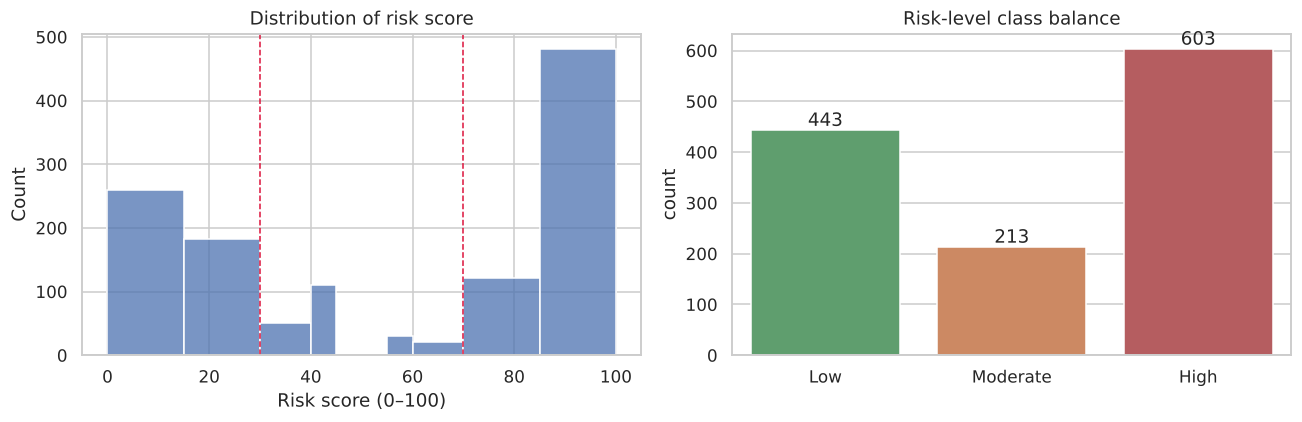

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_score, bins=[0, 15, 30, 40, 45, 55, 60, 70, 85, 100], ax=ax[0], color="#4C72B0")
ax[0].set_title("Distribution of risk score"); ax[0].set_xlabel("Risk score (0–100)")
for edge in (30, 70): ax[0].axvline(edge, color="crimson", ls="--", lw=1)

sns.countplot(x=y_class.map(dict(enumerate(LEVELS))), order=LEVELS, ax=ax[1],
              palette=["#55A868", "#DD8452", "#C44E52"])
ax[1].set_title("Risk-level class balance"); ax[1].set_xlabel("")
for p in ax[1].patches:
    ax[1].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

Note: respondents who answer 'Yes' to benefits / care options score HIGHER, not lower. This is a selection effect -
people already living with a condition are the ones who know about (and use) the support, so the association is not causal.


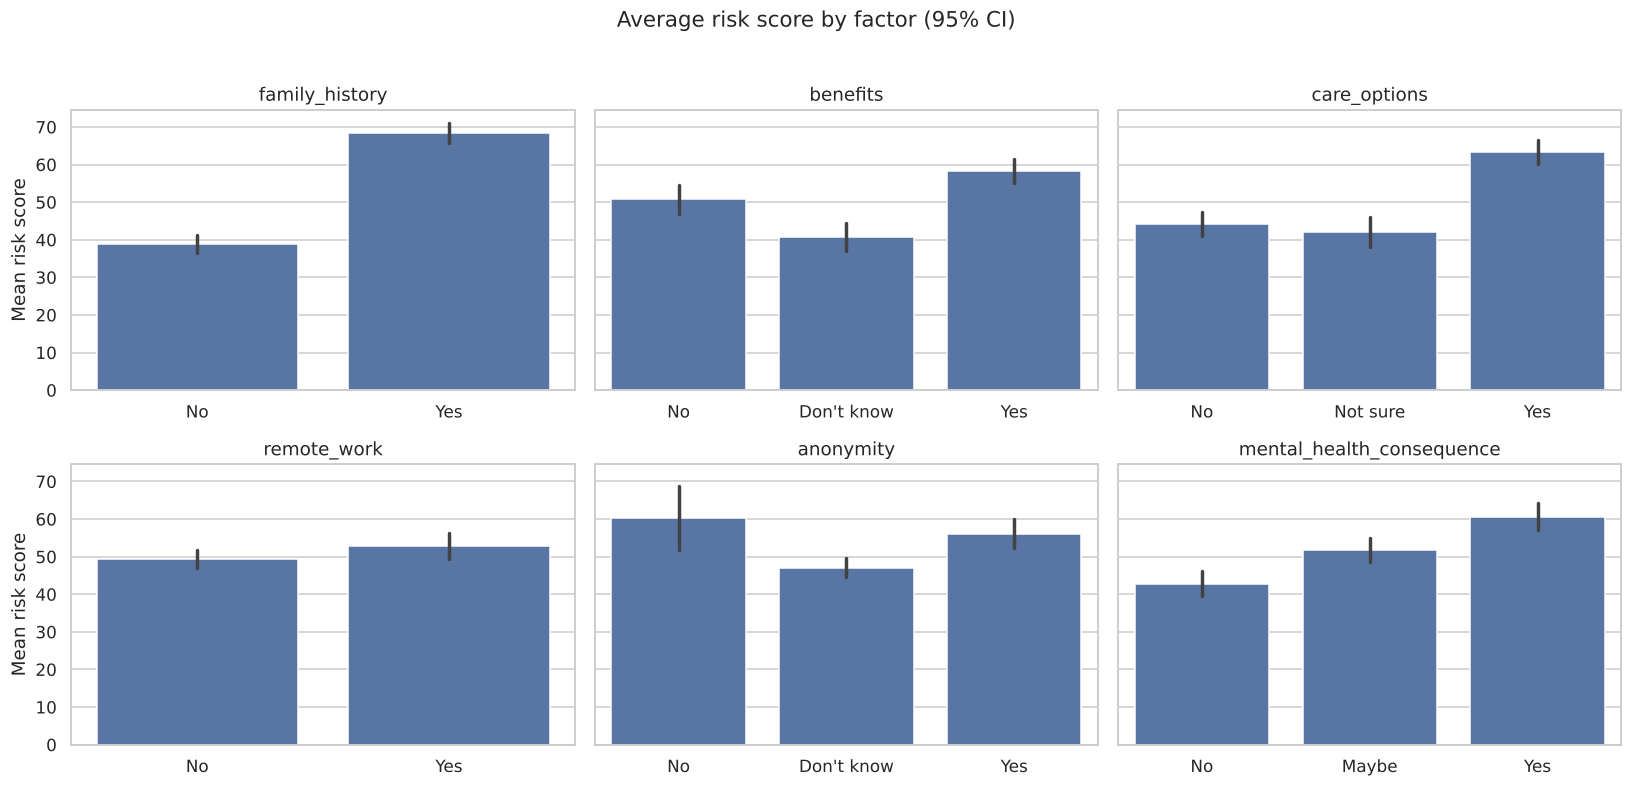

In [10]:
# Mean risk score by workplace / background factors (using the readable, un-encoded answers)
factors = ["family_history", "benefits", "care_options", "remote_work", "anonymity", "mental_health_consequence"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, col in zip(axes.ravel(), factors):
    order = [k for k, _ in sorted(ORDINAL_MAPS[col].items(), key=lambda kv: kv[1]) if k in set(df_clean[col])]
    tmp = pd.DataFrame({col: df_clean[col], "risk": y_score})
    sns.barplot(data=tmp, x=col, y="risk", order=order, ax=ax, errorbar=("ci", 95), color="#4C72B0")
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("Mean risk score")
plt.suptitle("Average risk score by factor (95% CI)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()
print("Note: respondents who answer 'Yes' to benefits / care options score HIGHER, not lower. This is a selection effect -")
print("people already living with a condition are the ones who know about (and use) the support, so the association is not causal.")

        count  mean
Gender             
Female    247  62.3
Male      992  46.9
Other      20  74.8


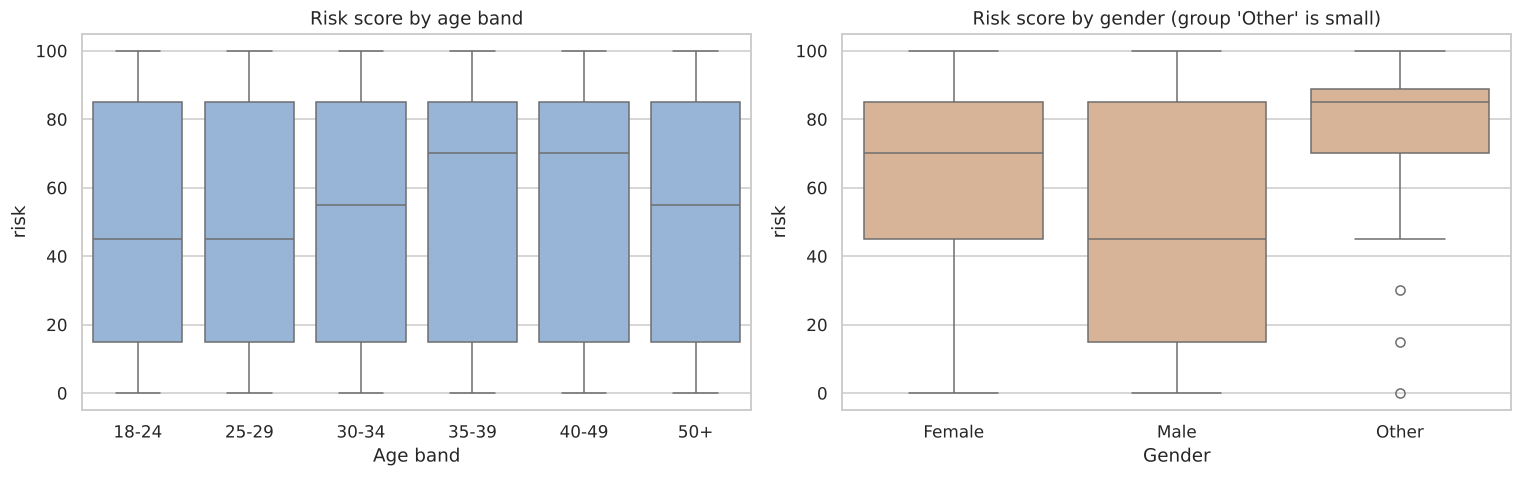

In [11]:
tmp = pd.DataFrame({"risk": y_score, "Gender": df_clean["Gender"],
                    "Age band": pd.cut(df_clean["Age"], [17, 24, 29, 34, 39, 49, 75],
                                       labels=["18-24", "25-29", "30-34", "35-39", "40-49", "50+"])})
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=tmp, x="Age band", y="risk", ax=ax[0], color="#8DB3E2"); ax[0].set_title("Risk score by age band")
sns.boxplot(data=tmp, x="Gender", y="risk", order=["Female", "Male", "Other"], ax=ax[1], color="#E2B38D")
ax[1].set_title("Risk score by gender (group 'Other' is small)")
plt.tight_layout(); plt.show()
print(tmp.groupby("Gender")["risk"].agg(["count", "mean"]).round(1))

Top 10 features by |Spearman correlation| with risk score:
family_history               0.376
care_options                 0.213
obs_consequence              0.192
mental_health_consequence    0.188
Gender_Male                 -0.172
Gender_Female                0.149
leave                       -0.100
benefits                     0.094
mental_vs_physical          -0.092
Country_Other               -0.092


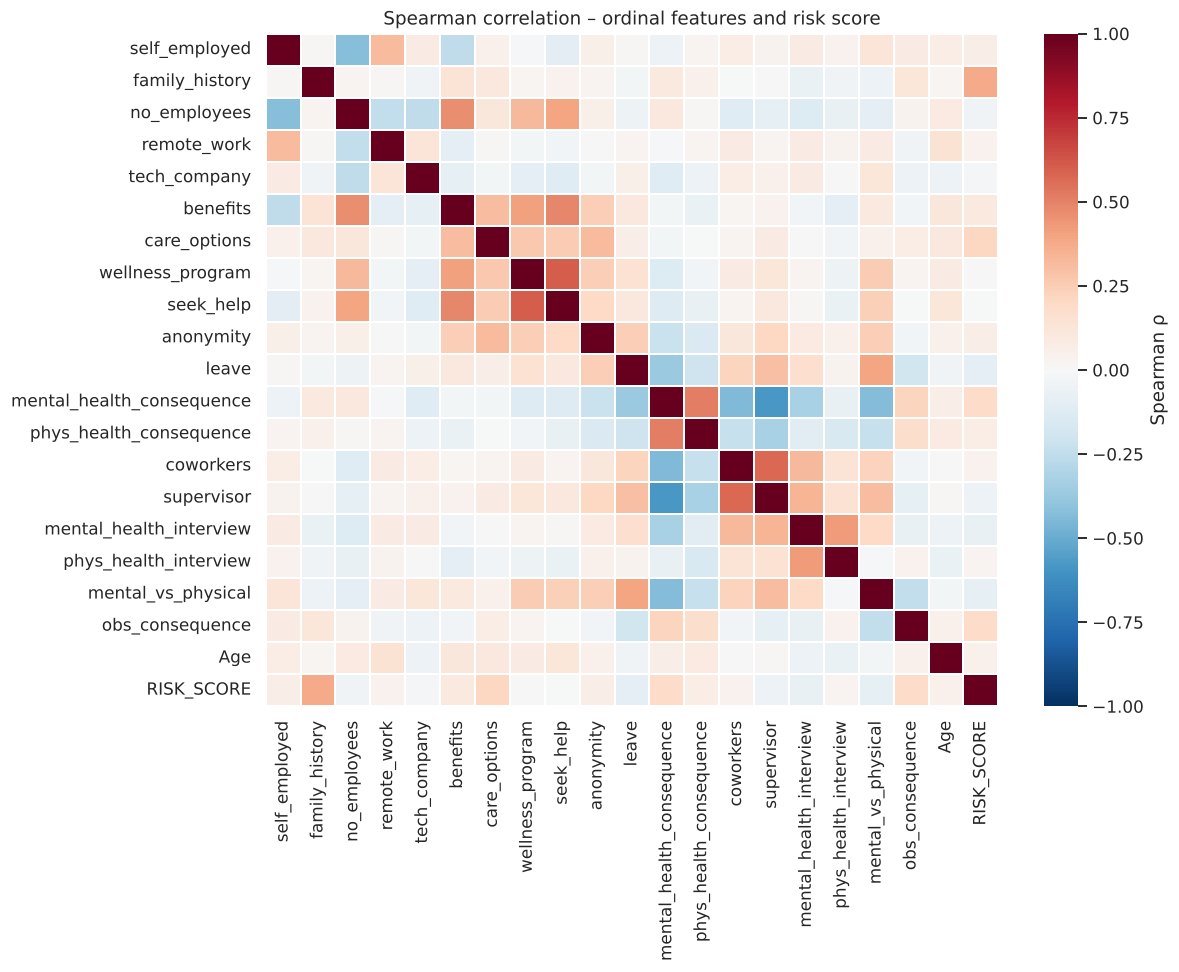

In [12]:
# Spearman correlation (appropriate for ordinal data) between every feature and the risk score
corr_with_target = pd.Series({c: spearmanr(X[c], y_score, nan_policy="omit")[0] for c in X.columns}).sort_values(key=abs, ascending=False)
print("Top 10 features by |Spearman correlation| with risk score:")
print(corr_with_target.head(10).round(3).to_string())

ordinal_cols = [c for c in X.columns if c in ORDINAL_MAPS] + ["Age"]
plt.figure(figsize=(11, 9))
sns.heatmap(X[ordinal_cols].assign(RISK_SCORE=y_score).corr(method="spearman"), cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.3, cbar_kws={"label": "Spearman ρ"})
plt.title("Spearman correlation – ordinal features and risk score"); plt.tight_layout(); plt.show()

## 9 · Train / test split
80 / 20, **stratified on risk level** so each class keeps the same proportion. The test set is locked away until the final evaluation –
feature selection and hyper-parameter tuning only ever see the training portion.

In [13]:
X_train, X_test, yc_train, yc_test, ys_train, ys_test = train_test_split(
    X, y_class, y_score, test_size=0.20, stratify=y_class, random_state=SEED)

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
pd.DataFrame({"train_%": (yc_train.value_counts(normalize=True).sort_index() * 100).round(1),
              "test_%":  (yc_test.value_counts(normalize=True).sort_index() * 100).round(1)}
             ).rename(index=dict(enumerate(LEVELS)))

Train: (1007, 28)   Test: (252, 28)


,train_%,test_%
risk_level,,
Low,35.2,35.3
Moderate,17.0,16.7
High,47.9,48.0


## 10 · Feature selection (three stages, training data only)
| Stage | Method | Purpose |
|---|---|---|
| 1. Filter | Mutual information with the risk level | Drop features carrying (almost) no signal |
| 2. Embedded | Random-forest impurity importance | Rank the survivors |
| 3. Wrapper | RFECV (recursive elimination, 5-fold CV, macro-F1) | Choose the final subset size |

Kept 18 of 28 features.
Dropped (MI < 0.005): ['phys_health_interview', 'Gender_Other', 'phys_health_consequence', 'remote_work', 'Country_Canada', 'self_employed', 'tech_company', 'Country_United Kingdom', 'Country_Germany', 'Age']


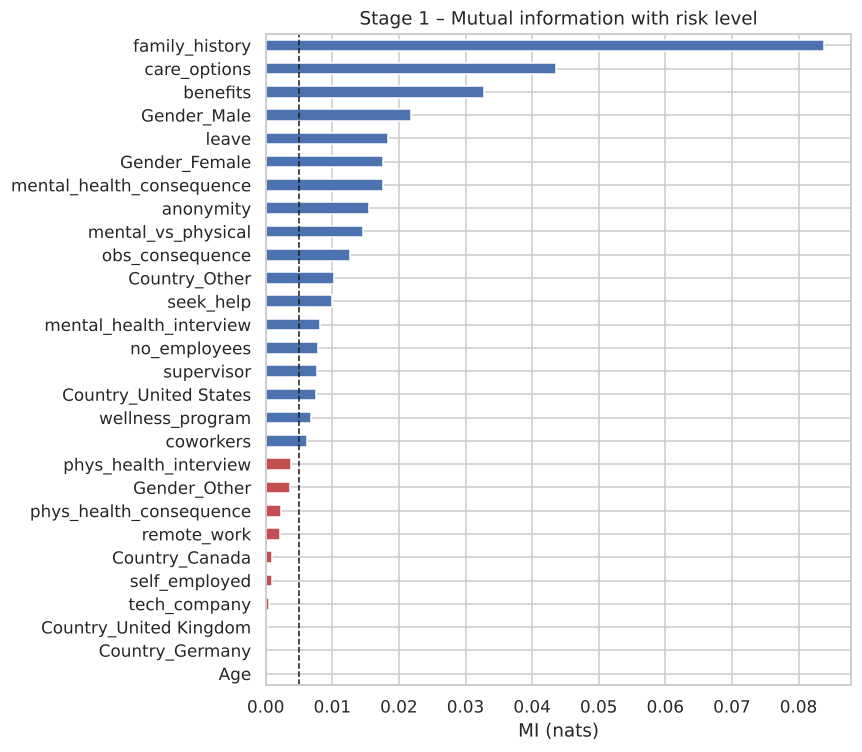

In [14]:
# Stage 1 – mutual information (Age needs a temporary median fill; the others are discrete)
imp = SimpleImputer(strategy="median").fit(X_train)
X_train_imp = pd.DataFrame(imp.transform(X_train), columns=X_train.columns, index=X_train.index)

discrete_mask = [c != "Age" for c in X_train.columns]
mi = pd.Series(mutual_info_classif(X_train_imp, yc_train, discrete_features=discrete_mask, random_state=SEED),
               index=X_train.columns).sort_values(ascending=False)

MI_THRESHOLD = 0.005
stage1_features = mi[mi >= MI_THRESHOLD].index.tolist()
dropped_stage1 = mi[mi < MI_THRESHOLD].index.tolist()

fig, ax = plt.subplots(figsize=(8, 7))
mi.sort_values().plot.barh(ax=ax, color=["#C44E52" if v < MI_THRESHOLD else "#4C72B0" for v in mi.sort_values()])
ax.axvline(MI_THRESHOLD, color="k", ls="--", lw=1); ax.set_title("Stage 1 – Mutual information with risk level")
ax.set_xlabel("MI (nats)"); plt.tight_layout(); plt.show()

print(f"Kept {len(stage1_features)} of {X_train.shape[1]} features.")
print("Dropped (MI < %.3f):" % MI_THRESHOLD, dropped_stage1)

,importance
family_history,0.1293
no_employees,0.1014
care_options,0.0908
leave,0.0857
mental_health_consequence,0.0705
benefits,0.0633
supervisor,0.0587
mental_vs_physical,0.0534
coworkers,0.0514
seek_help,0.0485


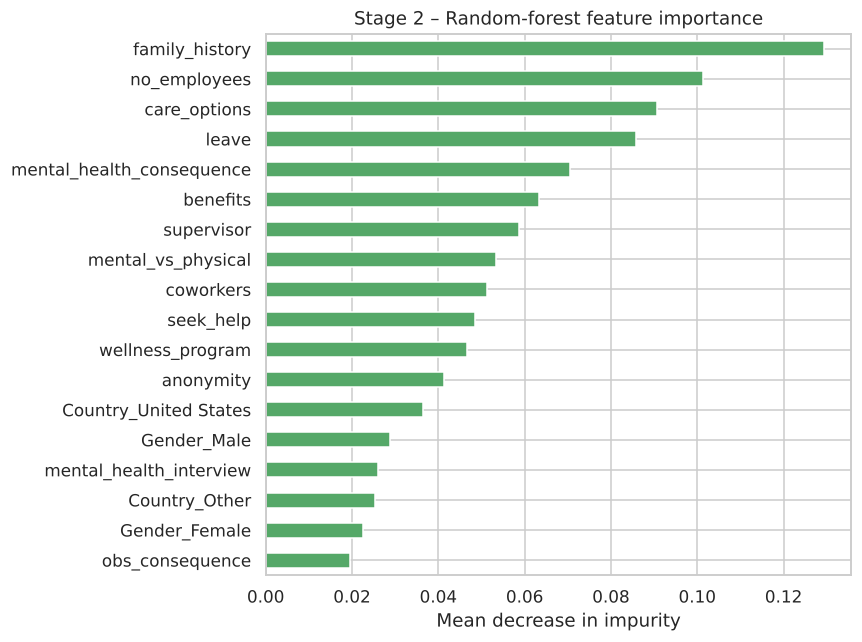

In [15]:
# Stage 2 – random-forest importance on the stage-1 survivors
rf_rank = RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced",
                                 random_state=SEED, n_jobs=-1).fit(X_train_imp[stage1_features], yc_train)
rf_imp = pd.Series(rf_rank.feature_importances_, index=stage1_features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
rf_imp.sort_values().plot.barh(ax=ax, color="#55A868")
ax.set_title("Stage 2 – Random-forest feature importance"); ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout(); plt.show()
rf_imp.head(10).round(4).to_frame("importance")

RFECV selected 15 features (best CV macro-F1 = 0.533):
['family_history', 'care_options', 'benefits', 'Gender_Male', 'leave', 'mental_health_consequence', 'anonymity', 'mental_vs_physical', 'seek_help', 'mental_health_interview', 'no_employees', 'supervisor', 'Country_United States', 'wellness_program', 'coworkers']


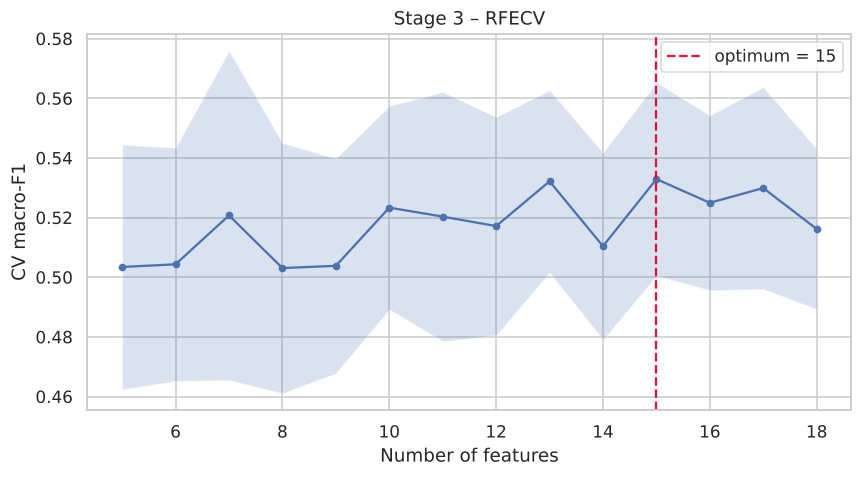

In [16]:
# Stage 3 – RFECV picks the subset size that maximises cross-validated macro-F1
rfecv = RFECV(
    estimator=RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=3,
                                     class_weight="balanced", random_state=SEED, n_jobs=-1),
    step=1, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    scoring="f1_macro", min_features_to_select=5, n_jobs=-1)
rfecv.fit(X_train_imp[stage1_features], yc_train)

selected_features = [f for f, keep in zip(stage1_features, rfecv.support_) if keep]
cv_curve = pd.DataFrame({"n_features": range(5, 5 + len(rfecv.cv_results_["mean_test_score"])),
                         "f1_macro": rfecv.cv_results_["mean_test_score"],
                         "std": rfecv.cv_results_["std_test_score"]})

plt.figure(figsize=(8, 4.5))
plt.plot(cv_curve["n_features"], cv_curve["f1_macro"], marker="o", ms=4)
plt.fill_between(cv_curve["n_features"], cv_curve["f1_macro"] - cv_curve["std"],
                 cv_curve["f1_macro"] + cv_curve["std"], alpha=0.2)
plt.axvline(rfecv.n_features_, color="crimson", ls="--", label=f"optimum = {rfecv.n_features_}")
plt.xlabel("Number of features"); plt.ylabel("CV macro-F1"); plt.title("Stage 3 – RFECV")
plt.legend(); plt.tight_layout(); plt.show()

print(f"RFECV selected {len(selected_features)} features (best CV macro-F1 = {cv_curve['f1_macro'].max():.3f}):")
print(selected_features)

In [17]:
# Consolidated feature-selection report
report = pd.DataFrame({"mutual_info": mi, "rf_importance": rf_imp}).fillna(0)
report["stage1_pass"] = report.index.isin(stage1_features)
report["selected_final"] = report.index.isin(selected_features)
report = report.sort_values(["selected_final", "rf_importance"], ascending=False)

X_train_sel, X_test_sel = X_train[selected_features], X_test[selected_features]
print(f"Final feature set: {len(selected_features)} of {X.shape[1]} original features")
report.round(4)

Final feature set: 15 of 28 original features


,mutual_info,rf_importance,stage1_pass,selected_final
family_history,0.0838,0.1293,True,True
no_employees,0.0078,0.1014,True,True
care_options,0.0436,0.0908,True,True
leave,0.0184,0.0857,True,True
mental_health_consequence,0.0176,0.0705,True,True
benefits,0.0327,0.0633,True,True
supervisor,0.0077,0.0587,True,True
mental_vs_physical,0.0146,0.0534,True,True
coworkers,0.0062,0.0514,True,True
seek_help,0.0100,0.0485,True,True


## 11 · Multi-class classification – Low / Moderate / High risk
Candidates are compared with **stratified 5-fold CV on the training set**. Every model sits inside a `Pipeline` with a median imputer
(and a scaler for the linear model) so preprocessing is re-fit inside each fold. Class weights handle the imbalance, and the
primary metric is **macro-F1** so the smaller *Moderate* class is not ignored.

In [18]:
def make_pipe(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

clf_candidates = {
    "Baseline (majority)":  make_pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression":  make_pipe(LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5), scale=True),
    "Random Forest":        make_pipe(RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                             class_weight="balanced", random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":    make_pipe(GradientBoostingClassifier(random_state=SEED)),
}

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy", "f1_macro": "f1_macro"}

rows = {}
for name, pipe in clf_candidates.items():
    cv = cross_validate(pipe, X_train_sel, yc_train, cv=skf, scoring=scoring, n_jobs=-1)
    rows[name] = {m: f"{cv['test_' + m].mean():.3f} ± {cv['test_' + m].std():.3f}" for m in scoring}
    rows[name]["_f1"] = cv["test_f1_macro"].mean()

clf_cv = pd.DataFrame(rows).T.sort_values("_f1", ascending=False)
best_clf_name = clf_cv.drop(index="Baseline (majority)").index[0]
print("Best classifier by CV macro-F1:", best_clf_name)
clf_cv.drop(columns="_f1")

Best classifier by CV macro-F1: Logistic Regression


,accuracy,balanced_acc,f1_macro
Logistic Regression,0.569 ± 0.051,0.524 ± 0.041,0.519 ± 0.039
Random Forest,0.582 ± 0.023,0.518 ± 0.026,0.515 ± 0.024
Gradient Boosting,0.604 ± 0.015,0.496 ± 0.013,0.479 ± 0.022
Baseline (majority),0.479 ± 0.001,0.333 ± 0.000,0.216 ± 0.000


In [19]:
# Hyper-parameter tuning of the best candidate
param_grids = {
    "Logistic Regression": {"model__C": [0.005, 0.01, 0.02, 0.05, 0.1, 0.5, 1, 5]},
    "Random Forest": {"model__n_estimators": [300, 600], "model__max_depth": [None, 6, 10],
                      "model__min_samples_leaf": [2, 3, 5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1],
                          "model__max_depth": [2, 3]},
}
clf_search = GridSearchCV(clf_candidates[best_clf_name], param_grids[best_clf_name],
                          cv=skf, scoring="f1_macro", n_jobs=-1, refit=True)
clf_search.fit(X_train_sel, yc_train)

best_clf = clf_search.best_estimator_
print("Tuned model      :", best_clf_name)
print("Best parameters  :", clf_search.best_params_)
print(f"CV macro-F1      : {clf_search.best_score_:.3f}")

Tuned model      : Logistic Regression
Best parameters  : {'model__C': 0.02}
CV macro-F1      : 0.522


In [20]:
# Final hold-out evaluation
pred_c = best_clf.predict(X_test_sel)
proba_c = best_clf.predict_proba(X_test_sel)

clf_metrics = {
    "accuracy":           accuracy_score(yc_test, pred_c),
    "balanced_accuracy":  balanced_accuracy_score(yc_test, pred_c),
    "macro_F1":           f1_score(yc_test, pred_c, average="macro"),
    "weighted_kappa":     cohen_kappa_score(yc_test, pred_c, weights="quadratic"),   # respects Low<Moderate<High order
    "ROC_AUC_ovr_macro":  roc_auc_score(yc_test, proba_c, multi_class="ovr", average="macro"),
}
print("TEST-SET CLASSIFICATION METRICS")
print(pd.Series(clf_metrics).round(3).to_string())
print("\n" + classification_report(yc_test, pred_c, target_names=LEVELS, digits=3))

TEST-SET CLASSIFICATION METRICS
accuracy             0.563
balanced_accuracy    0.515
macro_F1             0.511
weighted_kappa       0.445
ROC_AUC_ovr_macro    0.692

              precision    recall  f1-score   support

         Low      0.559     0.640     0.597        89
    Moderate      0.236     0.310     0.268        42
        High      0.758     0.595     0.667       121

    accuracy                          0.563       252
   macro avg      0.518     0.515     0.511       252
weighted avg      0.601     0.563     0.576       252


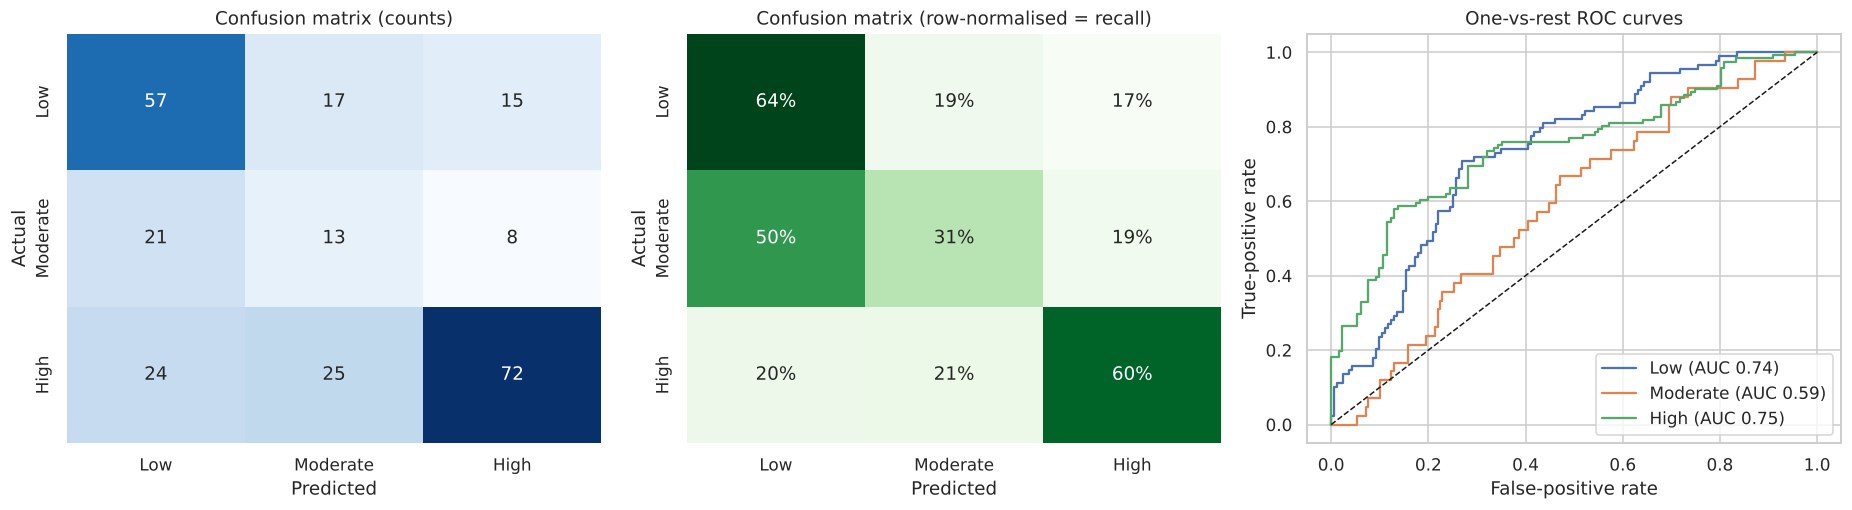

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cm = confusion_matrix(yc_test, pred_c)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LEVELS, yticklabels=LEVELS, ax=ax[0], cbar=False)
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".0%", cmap="Greens", xticklabels=LEVELS,
            yticklabels=LEVELS, ax=ax[1], cbar=False)
ax[1].set_title("Confusion matrix (row-normalised = recall)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")

Y_bin = label_binarize(yc_test, classes=[0, 1, 2])
for i, lvl in enumerate(LEVELS):
    fpr, tpr, _ = roc_curve(Y_bin[:, i], proba_c[:, i])
    ax[2].plot(fpr, tpr, label=f"{lvl} (AUC {roc_auc_score(Y_bin[:, i], proba_c[:, i]):.2f})")
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set_title("One-vs-rest ROC curves")
ax[2].set_xlabel("False-positive rate"); ax[2].set_ylabel("True-positive rate"); ax[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 12 · Regression – continuous 0–100 risk score
Same protocol, this time predicting the numeric score. Metrics: **RMSE, MAE, R²**.

In [22]:
reg_candidates = {
    "Baseline (mean)":    make_pipe(DummyRegressor(strategy="mean")),
    "Ridge Regression":   make_pipe(Ridge(alpha=10.0), scale=True),
    "Random Forest":      make_pipe(RandomForestRegressor(n_estimators=400, min_samples_leaf=3, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":  make_pipe(GradientBoostingRegressor(random_state=SEED)),
}
kf = KFold(5, shuffle=True, random_state=SEED)
reg_scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

rows = {}
for name, pipe in reg_candidates.items():
    cv = cross_validate(pipe, X_train_sel, ys_train, cv=kf, scoring=reg_scoring, n_jobs=-1)
    rows[name] = {"RMSE": f"{-cv['test_rmse'].mean():.2f} ± {cv['test_rmse'].std():.2f}",
                  "MAE":  f"{-cv['test_mae'].mean():.2f} ± {cv['test_mae'].std():.2f}",
                  "R²":   f"{cv['test_r2'].mean():.3f} ± {cv['test_r2'].std():.3f}",
                  "_r2":  cv["test_r2"].mean()}

reg_cv = pd.DataFrame(rows).T.sort_values("_r2", ascending=False)
best_reg_name = reg_cv.drop(index="Baseline (mean)").index[0]
print("Best regressor by CV R²:", best_reg_name)
reg_cv.drop(columns="_r2")

Best regressor by CV R²: Ridge Regression


,RMSE,MAE,R²
Ridge Regression,32.06 ± 1.10,27.05 ± 0.92,0.225 ± 0.052
Gradient Boosting,32.26 ± 1.34,26.64 ± 0.80,0.215 ± 0.068
Random Forest,32.65 ± 1.32,26.85 ± 1.15,0.196 ± 0.062
Baseline (mean),36.54 ± 0.50,33.59 ± 0.80,-0.005 ± 0.005


In [23]:
reg_grids = {
    "Ridge Regression": {"model__alpha": [1, 10, 50, 100, 200, 500]},
    "Random Forest": {"model__n_estimators": [300, 600], "model__max_depth": [None, 6, 10],
                      "model__min_samples_leaf": [3, 5, 10]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1],
                          "model__max_depth": [2, 3]},
}
reg_search = GridSearchCV(reg_candidates[best_reg_name], reg_grids[best_reg_name], cv=kf,
                          scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
reg_search.fit(X_train_sel, ys_train)
best_reg = reg_search.best_estimator_

print("Tuned model     :", best_reg_name)
print("Best parameters :", reg_search.best_params_)
print(f"CV RMSE         : {-reg_search.best_score_:.2f}")

Tuned model     : Ridge Regression
Best parameters : {'model__alpha': 50}
CV RMSE         : 32.03


In [24]:
pred_s = np.clip(best_reg.predict(X_test_sel), 0, 100)

reg_metrics = {
    "RMSE":     float(np.sqrt(mean_squared_error(ys_test, pred_s))),
    "MAE":      mean_absolute_error(ys_test, pred_s),
    "R2":       r2_score(ys_test, pred_s),
    "Spearman": spearmanr(ys_test, pred_s)[0],
}
baseline_rmse = float(np.sqrt(mean_squared_error(ys_test, np.full_like(ys_test, ys_train.mean(), dtype=float))))
print("TEST-SET REGRESSION METRICS")
print(pd.Series(reg_metrics).round(3).to_string())
print(f"\nBaseline RMSE (always predict the training mean): {baseline_rmse:.2f}")

# Use the regressor's score as a classifier too: convert predicted score → level
level_from_score = score_to_level(pred_s)
print("\nRegressor score → level:  accuracy = %.3f | macro-F1 = %.3f | weighted kappa = %.3f" % (
    accuracy_score(yc_test, level_from_score), f1_score(yc_test, level_from_score, average="macro"),
    cohen_kappa_score(yc_test, level_from_score, weights="quadratic")))
print("For reference, always predicting the majority level gives accuracy = %.3f" % (yc_test == yc_train.mode()[0]).mean())
print("→ Regression scores are compressed towards the mean, so levels should come from the classifier, not from cutting the score.")

TEST-SET REGRESSION METRICS
RMSE        33.027
MAE         28.523
R2           0.220
Spearman     0.458

Baseline RMSE (always predict the training mean): 37.41

Regressor score → level:  accuracy = 0.317 | macro-F1 = 0.322 | weighted kappa = 0.291
For reference, always predicting the majority level gives accuracy = 0.480
→ Regression scores are compressed towards the mean, so levels should come from the classifier, not from cutting the score.


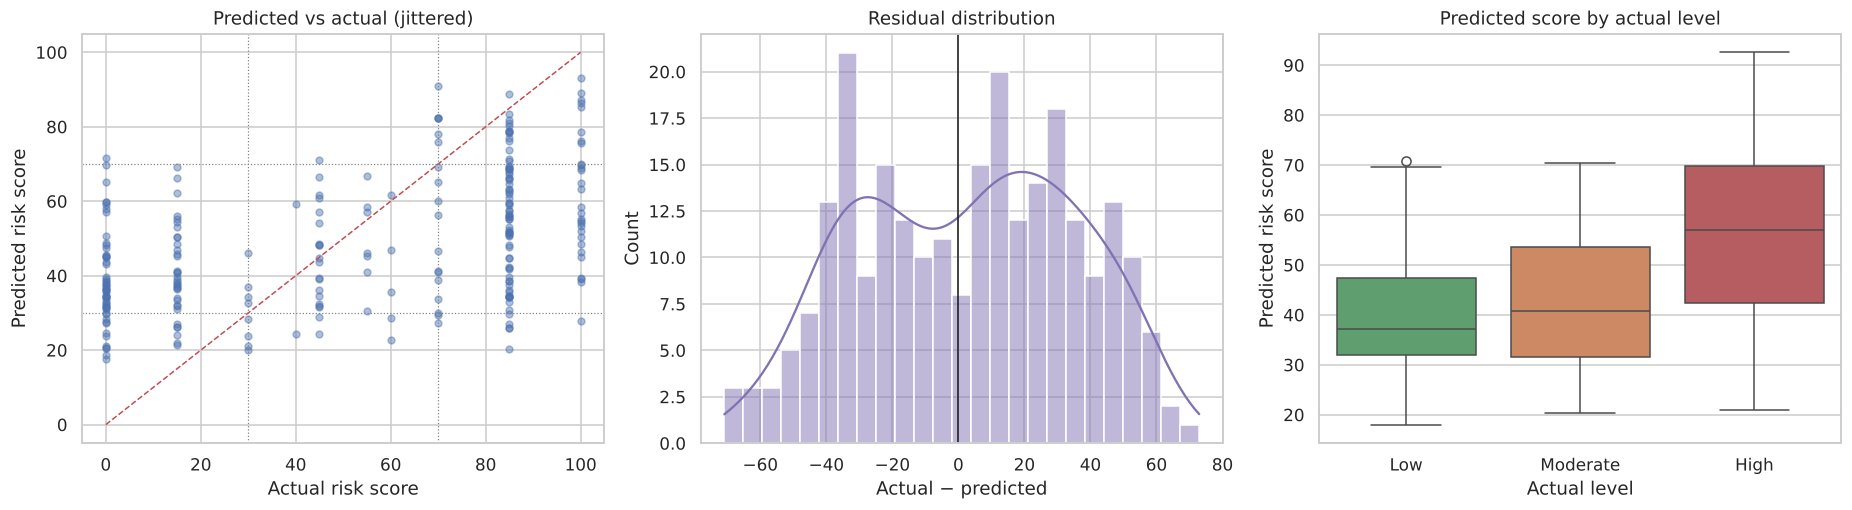

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(ys_test, pred_s + np.random.normal(0, 0.8, len(pred_s)), alpha=0.45, s=20)
ax[0].plot([0, 100], [0, 100], "r--", lw=1)
for edge in (30, 70): ax[0].axhline(edge, color="grey", ls=":", lw=0.8); ax[0].axvline(edge, color="grey", ls=":", lw=0.8)
ax[0].set_xlabel("Actual risk score"); ax[0].set_ylabel("Predicted risk score"); ax[0].set_title("Predicted vs actual (jittered)")

resid = ys_test - pred_s
sns.histplot(resid, bins=25, kde=True, ax=ax[1], color="#8172B2"); ax[1].axvline(0, color="k", lw=1)
ax[1].set_title("Residual distribution"); ax[1].set_xlabel("Actual − predicted")

order = pd.Series(yc_test.map(dict(enumerate(LEVELS))).values, name="Actual level")
sns.boxplot(x=order, y=pred_s, order=LEVELS, ax=ax[2], palette=["#55A868", "#DD8452", "#C44E52"])
ax[2].set_ylabel("Predicted risk score"); ax[2].set_title("Predicted score by actual level")
plt.tight_layout(); plt.show()

## 13 · Model interpretation – permutation importance
Computed on the **test set**: how much does performance drop when one feature is shuffled? This is model-agnostic and, unlike impurity
importance, is not biased towards high-cardinality features.

,clf_drop_in_macroF1,reg_drop_in_R2
family_history,0.1047,0.2065
care_options,0.0395,0.0240
mental_health_consequence,0.0392,0.0668
leave,0.0307,0.0187
coworkers,0.0252,0.0344
Country_United States,0.0228,0.0003
anonymity,0.0174,0.0019
Gender_Male,0.0133,0.0057
no_employees,0.0120,0.0179
benefits,0.0113,-0.0027


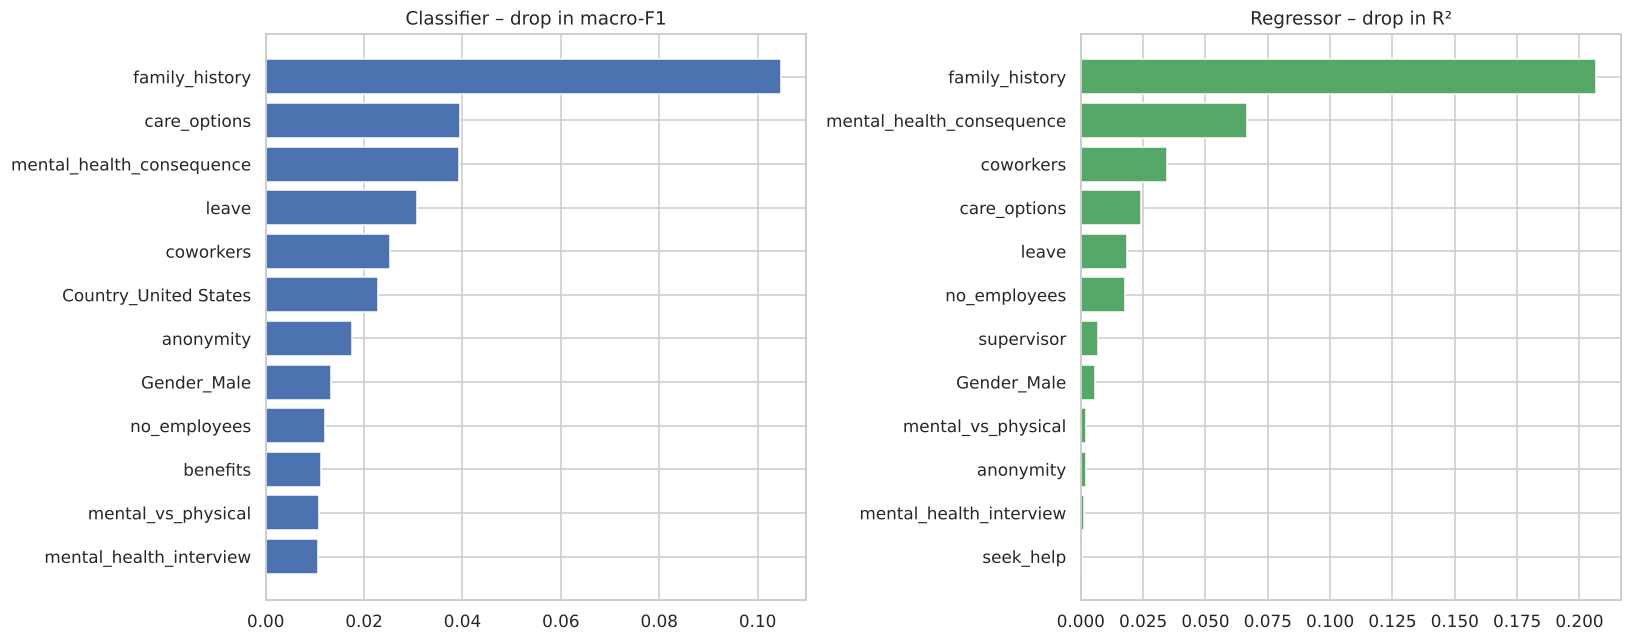

In [26]:
pi_clf = permutation_importance(best_clf, X_test_sel, yc_test, scoring="f1_macro", n_repeats=30, random_state=SEED, n_jobs=-1)
pi_reg = permutation_importance(best_reg, X_test_sel, ys_test, scoring="r2", n_repeats=30, random_state=SEED, n_jobs=-1)

imp_tbl = pd.DataFrame({
    "clf_drop_in_macroF1": pd.Series(pi_clf.importances_mean, index=selected_features),
    "reg_drop_in_R2":      pd.Series(pi_reg.importances_mean, index=selected_features),
}).sort_values("clf_drop_in_macroF1", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
top = imp_tbl.head(12)[::-1]
ax[0].barh(top.index, top["clf_drop_in_macroF1"], color="#4C72B0"); ax[0].set_title("Classifier – drop in macro-F1")
top = imp_tbl.sort_values("reg_drop_in_R2", ascending=False).head(12)[::-1]
ax[1].barh(top.index, top["reg_drop_in_R2"], color="#55A868"); ax[1].set_title("Regressor – drop in R²")
plt.tight_layout(); plt.show()
imp_tbl.head(10).round(4)

## 14 · Subgroup check
A screening model must not work well for some groups and badly for others. Here we compare test-set performance across gender and age band.
Small groups give noisy estimates, so the group size `n` is shown – treat groups with small `n` as indicative only.

In [27]:
test_meta = df_clean.loc[X_test.index, ["Gender", "Age"]].copy()
test_meta["Age band"] = pd.cut(test_meta["Age"], [17, 29, 39, 75], labels=["18-29", "30-39", "40+"]).astype(str)
test_meta["true"], test_meta["pred_c"], test_meta["pred_s"] = yc_test.values, pred_c, pred_s
test_meta["true_s"] = ys_test.values

def group_report(by):
    rows = []
    for g, d in test_meta.groupby(by):
        rows.append({by: g, "n": len(d), "accuracy": accuracy_score(d["true"], d["pred_c"]),
                     "macro_F1": f1_score(d["true"], d["pred_c"], average="macro"),
                     "MAE_score": mean_absolute_error(d["true_s"], d["pred_s"])})
    return pd.DataFrame(rows).set_index(by).round(3)

pd.concat({"By gender": group_report("Gender"), "By age band": group_report("Age band")})

n  accuracy  macro_F1  MAE_score
By gender   Female   39     0.718     0.519     25.675
            Male    211     0.531     0.490     29.109
            Other     2     1.000     1.000     22.210
By age band 18-29    98     0.592     0.556     27.702
            30-39   111     0.541     0.466     28.893
            40+      41     0.561     0.530     29.271

## 15 · Inference – score a new respondent and suggest an intervention tier
`predict_risk()` reuses the exact same cleaning → encoding → selected-feature → model path. It validates that all required survey
answers are present (a missing ordinal column silently becoming `0` would give a wrong answer, so it raises instead).

> This is a **screening aid** to prioritise outreach, not a diagnosis. Anyone flagged should be followed up by a qualified human.
>
> The **score** (regression) and the **level** (classification) come from two separate models. The level and the suggested action
> come from the classifier; the score is a finer-grained ranking and, being compressed towards the mean, may not line up exactly with the 30/70 cut-offs.

In [28]:
REQUIRED_INPUT_COLUMNS = [c for c in ORDINAL_MAPS if c not in LEAKY_COLUMNS] + ["Age", "Gender", "Country"]

INTERVENTIONS = {
    "Low":      "Routine wellness: share self-care resources (sleep, activity, stress management) and remind staff of existing support.",
    "Moderate": "Proactive check-in: offer EAP / counselling information, a manager 1:1 on workload, and a short follow-up survey in 4–6 weeks.",
    "High":     "Priority outreach: confidential counselling referral within days, review workplace adjustments, and human clinician follow-up.",
}

def predict_risk(responses, classifier=None, regressor=None):
    clf, reg = classifier or best_clf, regressor or best_reg
    raw = pd.DataFrame([responses]) if isinstance(responses, dict) else pd.DataFrame(responses).copy()
    absent = [c for c in REQUIRED_INPUT_COLUMNS if c not in raw.columns]
    if absent:
        raise ValueError(f"Missing required survey answers: {absent}")

    feats = encode_features(clean_survey(raw), feature_columns=selected_features)
    score = np.clip(reg.predict(feats), 0, 100)
    proba = clf.predict_proba(feats)
    level = proba.argmax(axis=1)

    result = pd.DataFrame({
        "risk_score (regressor)":   score.round(1),
        "risk_level (classifier)":  [LEVELS[i] for i in level],
        "P(Low)":       proba[:, 0].round(2), "P(Moderate)": proba[:, 1].round(2), "P(High)": proba[:, 2].round(2),
        "suggested_action": [INTERVENTIONS[LEVELS[i]] for i in level],
    })
    return result

# three illustrative respondents (answers to every non-target survey question)
base = dict(Age=33, Gender="Male", Country="United States", self_employed="No", remote_work="No", tech_company="Yes",
            obs_consequence="No", phys_health_consequence="No", mental_health_interview="No", phys_health_interview="Maybe",
            coworkers="Some of them", supervisor="Yes", mental_vs_physical="Yes")
profiles = pd.DataFrame([
    {**base, "family_history": "No",  "no_employees": "100-500",       "benefits": "Yes",        "care_options": "Yes",
     "wellness_program": "Yes",       "seek_help": "Yes",              "anonymity": "Yes",        "leave": "Very easy",
     "mental_health_consequence": "No"},
    {**base, "family_history": "Yes", "no_employees": "26-100",        "benefits": "Don't know", "care_options": "Not sure",
     "wellness_program": "No",        "seek_help": "Don't know",       "anonymity": "Don't know", "leave": "Somewhat difficult",
     "mental_health_consequence": "Maybe"},
    {**base, "Age": 29, "Gender": "Female", "family_history": "Yes", "no_employees": "1-5", "benefits": "No", "care_options": "No",
     "wellness_program": "No",        "seek_help": "No",              "anonymity": "No",         "leave": "Very difficult",
     "mental_health_consequence": "Yes", "obs_consequence": "Yes", "coworkers": "No", "supervisor": "No"},
], index=["A – supportive workplace", "B – mixed support, family history", "C – low support, family history"])

pd.set_option("display.max_colwidth", 140)
out = predict_risk(profiles); out.index = profiles.index
out

,risk_score (regressor),risk_level (classifier),P(Low),P(Moderate),P(High),suggested_action
A – supportive workplace,36.3,Low,0.52,0.24,0.24,"Routine wellness: share self-care resources (sleep, activity, stress management) and remind staff of existing support."
"B – mixed support, family history",63.3,High,0.20,0.31,0.50,"Priority outreach: confidential counselling referral within days, review workplace adjustments, and human clinician follow-up."
"C – low support, family history",68.7,High,0.12,0.42,0.46,"Priority outreach: confidential counselling referral within days, review workplace adjustments, and human clinician follow-up."


## 16 · Extending the pipeline with stress, sleep and physical-activity columns
The current file has none of these, but the encoder already knows how to handle them. A quick demonstration on three synthetic rows
(illustrative values only – not model inputs for this dataset):

In [29]:
demo = df_clean.head(3).copy()
demo["stress_level"]      = ["Low", "High", "Medium"]
demo["sleep_hours"]       = [8.0, 5.0, 6.5]
demo["physical_activity"] = ["High", "None", "Moderate"]

encode_features(demo)[["stress_level", "sleep_hours", "physical_activity"]]

,stress_level,sleep_hours,physical_activity
0,0.0,8.0,3.0
1,2.0,5.0,0.0
2,1.0,6.5,2.0


In [30]:
# To use them with real data: add the columns to the CSV, re-run from Cell 6 onward - they flow through
# encoding → feature selection → models with no code changes. Check what *would* be picked up:
optional_in_data = [c for c in list(OPTIONAL_ORDINAL_MAPS) + OPTIONAL_NUMERIC if c in df_raw.columns]
print("Optional lifestyle columns found in survey.csv:", optional_in_data if optional_in_data else "none")

Optional lifestyle columns found in survey.csv: none


## 17 · Save trained artifacts

In [31]:
joblib.dump(best_clf, f"{ARTIFACT_DIR}/risk_level_classifier.joblib")
joblib.dump(best_reg, f"{ARTIFACT_DIR}/risk_score_regressor.joblib")

metadata = {
    "classifier": best_clf_name, "regressor": best_reg_name,
    "selected_features": selected_features, "levels": LEVELS, "bin_edges": BIN_EDGES,
    "target_definition": f"100*({W_INTERFERE}*work_interfere/4 + {W_TREATMENT}*treatment)",
    "leaky_columns_excluded": LEAKY_COLUMNS,
    "test_metrics": {"classification": {k: round(v, 4) for k, v in clf_metrics.items()},
                     "regression":     {k: round(v, 4) for k, v in reg_metrics.items()}},
    "random_seed": SEED,
}
with open(f"{ARTIFACT_DIR}/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# reload to prove the saved model reproduces predictions
reloaded = joblib.load(f"{ARTIFACT_DIR}/risk_level_classifier.joblib")
assert (reloaded.predict(X_test_sel) == pred_c).all()
print("Saved files:", sorted(os.listdir(ARTIFACT_DIR)))
print("Reload check passed – identical predictions.")

Saved files: ['model_metadata.json', 'risk_level_classifier.joblib', 'risk_score_regressor.joblib']
Reload check passed – identical predictions.


## 18 · Final summary

In [32]:
summary = pd.DataFrame({
    "Task": ["Classification (Low/Moderate/High)"] * 3 + ["Regression (0–100 score)"] * 3,
    "Metric": ["Accuracy", "Macro-F1", "Weighted kappa", "RMSE", "MAE", "R²"],
    "Test value": [clf_metrics["accuracy"], clf_metrics["macro_F1"], clf_metrics["weighted_kappa"],
                   reg_metrics["RMSE"], reg_metrics["MAE"], reg_metrics["R2"]],
}).round(3)
print(f"Classifier: {best_clf_name} | Regressor: {best_reg_name} | Features used: {len(selected_features)}/{X.shape[1]}")
summary.set_index(["Task", "Metric"])

Classifier: Logistic Regression | Regressor: Ridge Regression | Features used: 15/28


Test value
Task                               Metric                    
Classification (Low/Moderate/High) Accuracy             0.563
                                   Macro-F1             0.511
                                   Weighted kappa       0.445
Regression (0–100 score)           RMSE                33.027
                                   MAE                 28.523
                                   R²                   0.220

### Limitations and next steps
* **The target is a proxy.** It is built from `work_interfere` and `treatment`, so the models predict *likelihood of reported impact / care-seeking*, not a clinical severity. Swap in a validated scale (PHQ-9, GAD-7, PSS-10) when available.
* **Missing lifestyle signals.** This file has no stress, sleep or exercise data; adding them is likely to improve accuracy, and the pipeline already supports them (Cells 6 and 29).
* **Self-selected 2014 tech-industry sample.** Performance may not transfer to other industries, countries or years – re-validate before any deployment.
* **Small gender-diverse subgroup.** Subgroup estimates (Cell 27) are noisy for the "Other" gender group.
* **Use for support, never for exclusion.** Scores should only trigger *offers* of confidential help, never hiring, promotion or performance decisions, and need consent, privacy and data-governance controls.
* Next steps: probability calibration, SHAP explanations, drift monitoring, and prospective validation with counsellors.